# Forest vs plantation: small neural net + Optuna (spatial CV)
Trains on the 1,700 train_eligible MapBiomas points, tunes with block-grouped CV,
then checks the best model once on QC dev. Lockbox and QC heldback are never touched (used for later testing).

In [2]:
# Install libraries
!pip install -q optuna
import numpy as np, pandas as pd, torch, torch.nn as nn, optuna
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

In [3]:
DATA = "master_features_v3_slim.csv"
# Cropin's baseline inputs; set to False to include
DROP_BENCHMARKS = True
# True = train only on non-border points
DROP_BORDER = False
N_TRIALS, N_FOLDS = 40, 5
# Early stopping: quit after 20 epochs with no AUC gain
MAX_EPOCHS, PATIENCE = 200, 20
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
# Use in training to test for improvement
MIN_DELTA = 0.001

In [4]:
# Load data (features vs bookkeeping columns)
META = ["uid", "set", "split", "label_forest", "train_eligible", "border", "block"]
BENCH = ["nc_A_SAG", "nc_chm_mean_r15", "nc_chm_stdDev_r15"] # Cropin's benchmark features

df = pd.read_csv(DATA)
feats = [c for c in df.columns if c not in META and not (DROP_BENCHMARKS and c in BENCH)]

train = df[df.train_eligible]
if DROP_BORDER:
    train = train[train.border == 0]
qc_dev = df[(df.set == "qc") & (df.split == "dev")]

X = train[feats].to_numpy(np.float32)
y = train["label_forest"].to_numpy(np.float32)
groups = train["block"].to_numpy()
print(f"{len(feats)} features, {len(train)} training points, {len(np.unique(groups))} blocks")

# Cross validate, separating on spatial blocks so no block is split between folds
# and stratified to keep forest class ratios similar across folds
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, y, groups))

31 features, 1700 training points, 167 blocks


In [5]:
# Setup model
class MLP(nn.Module):
    def __init__(self, n_in, hidden, n_layers, dropout):
        super().__init__()
        layers, d = [], n_in
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(dropout)]
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [6]:
# Convert to tensor
def to_tensor(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))

# Training run
def train_model(X_tr, y_tr, p, n_epochs, X_va=None, y_va=None):
    """Train for up to n_epochs. With a validation fold: early-stop on AUC and return
    (best_auc, best_epoch, hist), where hist holds per-epoch curves. Without one: return the model."""
    torch.manual_seed(SEED)
    model = MLP(X_tr.shape[1], p["hidden"], p["n_layers"], p["dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()

    Xt, yt = to_tensor(X_tr), to_tensor(y_tr)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=p["batch_size"], shuffle=True)
    if X_va is not None:
        Xv, yv = to_tensor(X_va), to_tensor(y_va)
    best_auc, best_epoch, bad = 0.0, 0, 0
    hist = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": []}

    for epoch in range(n_epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            W = model.net[0].weight              # L1 (group lasso) on first layer
            loss = loss + p["l1"] * W.norm(dim=0).sum()
            loss.backward()
            opt.step()

        if X_va is None:
            continue
        model.eval()
        with torch.no_grad():                  # record lossses and AUC for all batches
            lt, lv = model(Xt), model(Xv)
            hist["train_loss"].append(loss_fn(lt, yt).item())   # BCE only (no L1), so train/val comparable
            hist["val_loss"].append(loss_fn(lv, yv).item())
            hist["train_auc"].append(roc_auc_score(y_tr, torch.sigmoid(lt).cpu().numpy()))
            auc = roc_auc_score(y_va, torch.sigmoid(lv).cpu().numpy())
            hist["val_auc"].append(auc)
        if auc > best_auc + MIN_DELTA:     # Only accept meaningful change
          best_auc, best_epoch, bad = auc, epoch + 1, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    return (best_auc, best_epoch, hist) if X_va is not None else model

In [7]:
# Optuna objective to tune hyperparameters during CV (using metric mean AUC across spatial folds)
def objective(trial):
    p = {
        "hidden":       trial.suggest_int("hidden", 16, 128, log=True),
        "n_layers":     trial.suggest_int("n_layers", 1, 3),
        "dropout":      trial.suggest_float("dropout", 0.0, 0.5),
        "lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
        "l1":           trial.suggest_float("l1", 1e-6, 1e-2, log=True),   # lasso strength
    }
    aucs, epochs, hists = [], [], []
    for k, (tr, va) in enumerate(FOLDS):
        scaler = StandardScaler().fit(X[tr])   # fit on the training fold only
        auc, ep, h = train_model(scaler.transform(X[tr]), y[tr], p, MAX_EPOCHS,
                                 scaler.transform(X[va]), y[va])
        aucs.append(auc); epochs.append(ep); hists.append(h)
        trial.report(np.mean(aucs), k)         # lets the pruner stop weak trials early
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("epochs", int(np.mean(epochs)))
    trial.set_user_attr("hist", hists)         # saved curves for all 5 folds
    return float(np.mean(aucs))
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best = study.best_trial
print(f"Best CV AUC: {best.value:.3f}  epochs: {best.user_attrs['epochs']}")
print(best.params)

[I 2026-11-18 04:18:53,544] A new study created in memory with name: no-name-f60480f3-6c88-4560-803e-646c1beaa1af


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-11-18 04:19:16,962] Trial 0 finished with value: 0.990566915224027 and parameters: {'hidden': 49, 'n_layers': 3, 'dropout': 0.30138168803582194, 'lr': 0.001229607110732572, 'weight_decay': 4.9501595537331986e-05, 'batch_size': 128, 'l1': 0.0071556821617548725}. Best is trial 0 with value: 0.990566915224027.
[I 2026-11-18 04:19:26,756] Trial 1 finished with value: 0.9895572186314834 and parameters: {'hidden': 35, 'n_layers': 3, 'dropout': 0.26444745987645224, 'lr': 0.001368009527972693, 'weight_decay': 0.005039489598671216, 'batch_size': 64, 'l1': 0.002140323314098607}. Best is trial 0 with value: 0.990566915224027.
[I 2026-11-18 04:19:40,107] Trial 2 finished with value: 0.9903691170783354 and parameters: {'hidden': 80, 'n_layers': 3, 'dropout': 0.489309171116382, 'lr': 0.00396567508177101, 'weight_decay': 7.013219779945803e-05, 'batch_size': 32, 'l1': 3.7446665357415703e-06}. Best is trial 0 with value: 0.990566915224027.
[I 2026-11-18 04:19:54,416] Trial 3 finished with value

In [8]:
# Final model on all training points, with train + QC dev curves
import copy

def train_final(cols, p, keep_epoch):
    """Train on all training points, recording loss + AUC on train and QC dev each epoch.
    Runs past keep_epoch so you can see the full curve, but returns the weights FROM keep_epoch
    (chosen by CV). The QC dev curve is for viewing only, never for picking epochs."""
    Xg = train[cols].to_numpy(np.float32)
    sc = StandardScaler().fit(Xg)
    Xq = qc_dev[cols].to_numpy(np.float32)
    Xq = np.where(np.isnan(Xq), np.nanmedian(Xg, axis=0), Xq)     # one QC point lacks radar
    Xt, yt = to_tensor(sc.transform(Xg)), to_tensor(y)
    Xv, yv = to_tensor(sc.transform(Xq)), to_tensor(qc_dev["label_forest"].to_numpy())

    torch.manual_seed(SEED)
    model = MLP(Xg.shape[1], p["hidden"], p["n_layers"], p["dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=p["batch_size"], shuffle=True)

    n_epochs = min(MAX_EPOCHS, max(3 * keep_epoch, keep_epoch + 30))
    hist = {"train_loss": [], "test_loss": [], "train_auc": [], "test_auc": []}
    for epoch in range(n_epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb) + p["l1"] * model.net[0].weight.norm(dim=0).sum()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lt, lv = model(Xt), model(Xv)
            hist["train_loss"].append(loss_fn(lt, yt).item())
            hist["test_loss"].append(loss_fn(lv, yv).item())
            hist["train_auc"].append(roc_auc_score(y, torch.sigmoid(lt).cpu().numpy()))
            hist["test_auc"].append(roc_auc_score(qc_dev["label_forest"], torch.sigmoid(lv).cpu().numpy()))
        if epoch + 1 == keep_epoch:
            kept = copy.deepcopy(model.state_dict())   # snapshot of the final model

    model.load_state_dict(kept)
    model.cols, model.scaler, model.fill = cols, sc, np.nanmedian(Xg, axis=0)   # kept for predicting later
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(Xv)).cpu().numpy()
    return model, prob, hist

model, prob_q, hist_all = train_final(feats, best.params, best.user_attrs["epochs"])
print(f"QC dev AUC: {roc_auc_score(qc_dev['label_forest'], prob_q):.3f}")

QC dev AUC: 0.841


In [9]:
# Which features did the L1 penalty shrink?
w = model.net[0].weight.detach().norm(dim=0).cpu().numpy()
print(pd.Series(w, index=feats).sort_values(ascending=False).round(3).to_string())

rh_s_std                        0.922
nc_nfw                          0.680
nc_D_h_total_loss_px            0.526
nc_B_SAG_phase_sin              0.452
nc_E_eth_h                      0.383
nc_B_SAG_SON                    0.304
nc_B_SWIR_phase_sin             0.304
nc_D_cc_n_breaks                0.256
nc_D_lt_n_vertices              0.243
nc_B_NDRE_phase_sin             0.223
nc_D_years_continuous_forest    0.211
nc_F_VHminusVV_median           0.211
nc_D_ndvi_1985_89               0.206
nc_B_SWIR_phase_cos             0.204
rh_n_cycles                     0.201
nc_wi3_NDMI                     0.197
nc_sg3_NDVI                     0.188
nc_hansen_tc2000                0.173
nc_F_VH_median                  0.170
mm_NDVI_win                     0.169
mm_SAG_win                      0.167
lh_ever_open                    0.157
nc_D_max_nbr_drop               0.154
nc_su3_NDMI                     0.149
lh_n_changes                    0.148
mm_B6_win                       0.143
nc_E_eth_sd5

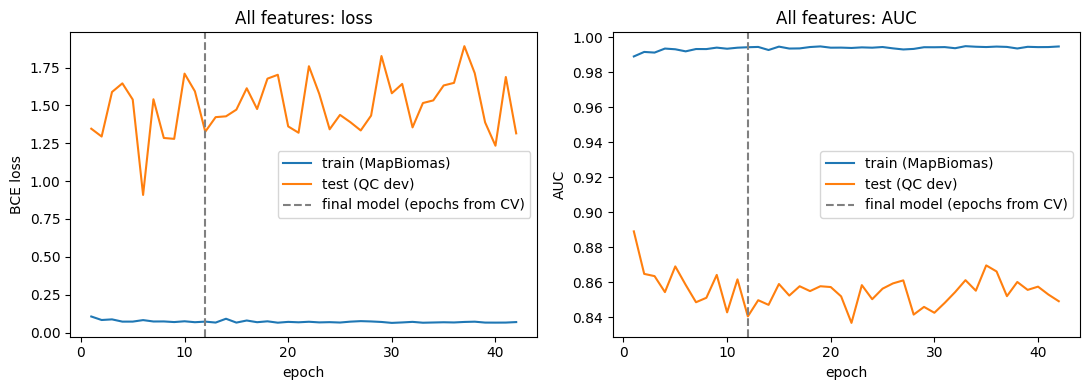

In [10]:
# Plot loss + AUC curves of the final model (train vs QC dev)
import matplotlib.pyplot as plt

def plot_final(hist, keep_epoch, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    a1.plot(ep, hist["train_loss"], label="train (MapBiomas)")
    a1.plot(ep, hist["test_loss"],  label="test (QC dev)")
    a2.plot(ep, hist["train_auc"],  label="train (MapBiomas)")
    a2.plot(ep, hist["test_auc"],   label="test (QC dev)")
    a1.set(xlabel="epoch", ylabel="BCE loss", title=f"{title}: loss")
    a2.set(xlabel="epoch", ylabel="AUC", title=f"{title}: AUC")
    for a in (a1, a2):
        a.axvline(keep_epoch, ls="--", c="gray", label="final model (epochs from CV)")
        a.legend()
    plt.tight_layout(); plt.show()

plot_final(hist_all, best.user_attrs["epochs"], "All features")

In [ ]:
# Cell 10: tune + fit a separate net on each feature group
HIST = [c for c in feats if c.startswith(("rh_", "lh_", "nc_D_", "nc_nfw"))]
SPEC = [c for c in feats if c not in HIST]
print(len(HIST), "history features |", len(SPEC), "spectral/radar/height features")

def suggest_params(trial):            # same search space as Cell 6
    return {
        "hidden":       trial.suggest_int("hidden", 16, 128, log=True),
        "n_layers":     trial.suggest_int("n_layers", 1, 3),
        "dropout":      trial.suggest_float("dropout", 0.0, 0.5),
        "lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
        "l1":           trial.suggest_float("l1", 1e-6, 1e-2, log=True),
    }

def fit_group(cols, name, n_trials=N_TRIALS):
    Xg = train[cols].to_numpy(np.float32)

    def objective(trial):             # same CV as Cell 6, on this group's columns only
        p = suggest_params(trial)
        aucs, eps, hists = [], [], []
        for k, (tr, va) in enumerate(FOLDS):
            sc = StandardScaler().fit(Xg[tr])
            auc, ep, h = train_model(sc.transform(Xg[tr]), y[tr], p, MAX_EPOCHS,
                                     sc.transform(Xg[va]), y[va])
            aucs.append(auc); eps.append(ep); hists.append(h)
            trial.report(np.mean(aucs), k)
            if trial.should_prune():
                raise optuna.TrialPruned()
        trial.set_user_attr("epochs", int(np.mean(eps)))
        trial.set_user_attr("hist", hists)
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    b = study.best_trial

    # final model on all training points + curves
    m, prob, hist = train_final(cols, b.params, b.user_attrs["epochs"])
    print(f"{name}: CV AUC {b.value:.3f} | QC dev AUC {roc_auc_score(qc_dev['label_forest'], prob):.3f}")
    return {"trial": b, "prob": prob, "cv": b.value, "hist": hist, "model": m}

res_hist = fit_group(HIST, "History")
res_spec = fit_group(SPEC, "Spectral")

[I 2026-11-18 04:28:26,831] A new study created in memory with name: no-name-a8984b42-f771-42de-8962-e7a6e3bd3c0b


14 history features | 17 spectral/radar/height features


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-11-18 04:28:35,320] Trial 0 finished with value: 0.9885531534585486 and parameters: {'hidden': 49, 'n_layers': 3, 'dropout': 0.30138168803582194, 'lr': 0.001229607110732572, 'weight_decay': 4.9501595537331986e-05, 'batch_size': 128, 'l1': 0.0071556821617548725}. Best is trial 0 with value: 0.9885531534585486.
[I 2026-11-18 04:28:45,415] Trial 1 finished with value: 0.9884095078163663 and parameters: {'hidden': 35, 'n_layers': 3, 'dropout': 0.26444745987645224, 'lr': 0.001368009527972693, 'weight_decay': 0.005039489598671216, 'batch_size': 64, 'l1': 0.002140323314098607}. Best is trial 0 with value: 0.9885531534585486.
[I 2026-11-18 04:28:57,434] Trial 2 finished with value: 0.9883107347904891 and parameters: {'hidden': 80, 'n_layers': 3, 'dropout': 0.489309171116382, 'lr': 0.00396567508177101, 'weight_decay': 7.013219779945803e-05, 'batch_size': 32, 'l1': 3.7446665357415703e-06}. Best is trial 0 with value: 0.9885531534585486.
[I 2026-11-18 04:29:10,933] Trial 3 finished with v

[I 2026-11-18 04:34:33,281] A new study created in memory with name: no-name-16496f97-b615-438b-b3f9-dd84fe3d05e5


History: CV AUC 0.989 | QC dev AUC 0.789


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-11-18 04:34:45,051] Trial 0 finished with value: 0.9602423691892449 and parameters: {'hidden': 49, 'n_layers': 3, 'dropout': 0.30138168803582194, 'lr': 0.001229607110732572, 'weight_decay': 4.9501595537331986e-05, 'batch_size': 128, 'l1': 0.0071556821617548725}. Best is trial 0 with value: 0.9602423691892449.
[I 2026-11-18 04:34:56,983] Trial 1 finished with value: 0.9577860484040304 and parameters: {'hidden': 35, 'n_layers': 3, 'dropout': 0.26444745987645224, 'lr': 0.001368009527972693, 'weight_decay': 0.005039489598671216, 'batch_size': 64, 'l1': 0.002140323314098607}. Best is trial 0 with value: 0.9602423691892449.
[I 2026-11-18 04:35:12,614] Trial 2 finished with value: 0.9606476384431796 and parameters: {'hidden': 80, 'n_layers': 3, 'dropout': 0.489309171116382, 'lr': 0.00396567508177101, 'weight_decay': 7.013219779945803e-05, 'batch_size': 32, 'l1': 3.7446665357415703e-06}. Best is trial 2 with value: 0.9606476384431796.
[I 2026-11-18 04:35:26,890] Trial 3 finished with v

                               CV AUC (MapBiomas)  QC dev AUC
All features (one net)                      0.993       0.841
History only                                0.989       0.789
Spectral only                               0.964       0.874
Average of history + spectral                 NaN       0.878
Correlation of history vs spectral predictions on QC dev: 0.42


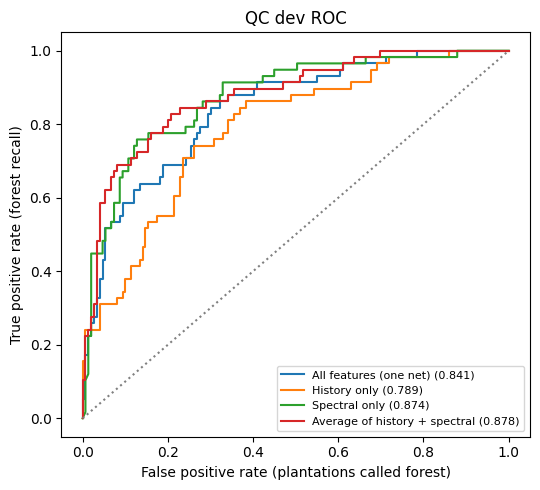

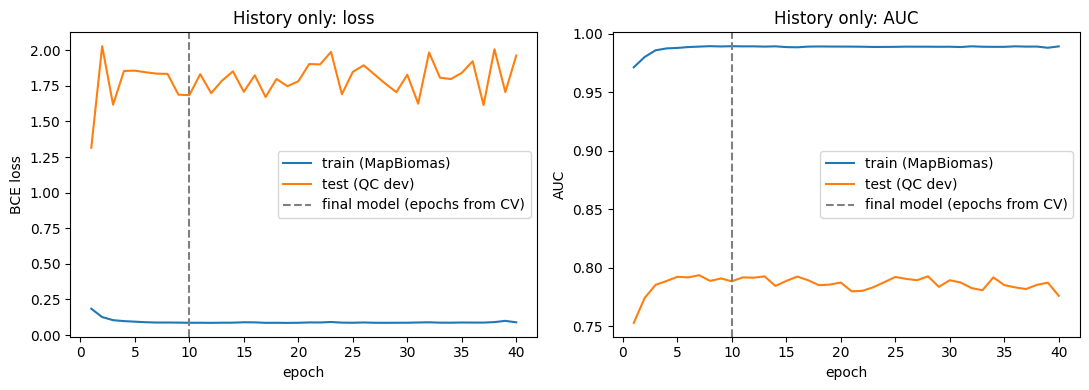

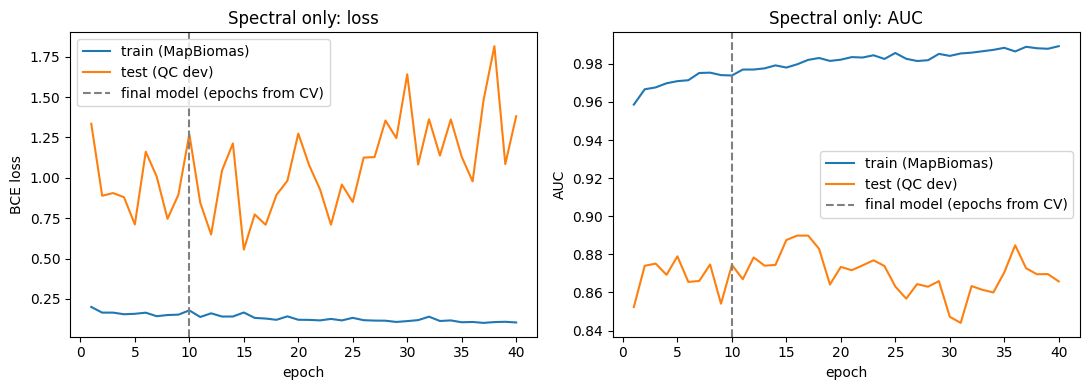

In [34]:
# Average the two nets and compare everything on QC dev
from sklearn.metrics import roc_curve

y_q = qc_dev["label_forest"].to_numpy()
prob_avg = (res_hist["prob"] + res_spec["prob"]) / 2      # equal weights, fixed in advance

results = {
    "All features (one net)":   (best.value,      prob_q),
    "History only":             (res_hist["cv"],  res_hist["prob"]),
    "Spectral only":            (res_spec["cv"],  res_spec["prob"]),
    "Average of history + spectral": (np.nan,     prob_avg),
}
print(pd.DataFrame({name: {"CV AUC (MapBiomas)": cv, "QC dev AUC": roc_auc_score(y_q, p)}
                    for name, (cv, p) in results.items()}).T.round(3))
print("Correlation of history vs spectral predictions on QC dev:",
      round(np.corrcoef(res_hist["prob"], res_spec["prob"])[0, 1], 2))

# ROC curves on QC dev
plt.figure(figsize=(5.5, 5))
for name, (_, p) in results.items():
    fpr, tpr, _ = roc_curve(y_q, p)
    plt.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_q, p):.3f})")
plt.plot([0, 1], [0, 1], ls=":", c="gray")
plt.xlabel("False positive rate (plantations called forest)")
plt.ylabel("True positive rate (forest recall)")
plt.title("QC dev ROC"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

# loss + AUC curves of each group's final net
plot_final(res_hist["hist"], res_hist["trial"].user_attrs["epochs"], "History only")
plot_final(res_spec["hist"], res_spec["trial"].user_attrs["epochs"], "Spectral only")

In [35]:
# FP / FN rates on QC dev (forest = positive)
FULL_DATA = "master_features_v3.csv"     # the full v3 file, only for MapBiomas's own prediction

def rates(y_true, pred):
    tp = int(((pred == 1) & (y_true == 1)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    return {"FP": fp, "FN": fn,
            "FP rate (plantations called forest)": fp / (fp + tn),
            "FN rate (forest missed)": fn / (fn + tp),
            "Forest recall": tp / (tp + fn),
            "Precision (calls of forest that are right)": tp / (tp + fp) if tp + fp else np.nan}

# Reference: MapBiomas's own map on the same points (map says plantation -> 0, else forest -> 1)
full = pd.read_csv(FULL_DATA).set_index("uid")
mb_pred = 1 - full.loc[qc_dev["uid"], "nc_H_mapbiomas10m_plantation"].to_numpy()
mb = rates(y_q, mb_pred)
print(f"QC dev: {int(y_q.sum())} forest, {int((1 - y_q).sum())} plantation points\n")

# A) every model at the default 0.5 threshold
rows = {"MapBiomas map (reference)": mb}
rows.update({name: rates(y_q, (p >= 0.5).astype(int)) for name, (_, p) in results.items()})
print("At threshold 0.5:")
print(pd.DataFrame(rows).T.round(3).to_string(), "\n")

# B) fair comparison: each model's FP rate when its forest recall is held at MapBiomas's level
target = mb["Forest recall"]
rows = {"MapBiomas map (reference)": {"threshold": np.nan, "Forest recall": target,
                                      "FP rate (plantations called forest)": mb["FP rate (plantations called forest)"]}}
for name, (_, p) in results.items():
    fpr, tpr, thr = roc_curve(y_q, p)
    i = np.argmax(tpr >= target)           # first threshold reaching the target recall
    rows[name] = {"threshold": thr[i], "Forest recall": tpr[i],
                  "FP rate (plantations called forest)": fpr[i]}
print(f"At matched forest recall (>= {target:.3f}, MapBiomas's level):")
print(pd.DataFrame(rows).T.round(3).to_string())

QC dev: 58 forest, 149 plantation points

At threshold 0.5:
                                  FP   FN  FP rate (plantations called forest)  FN rate (forest missed)  Forest recall  Precision (calls of forest that are right)
MapBiomas map (reference)      121.0  4.0                                0.812                    0.069          0.931                                       0.309
All features (one net)         103.0  2.0                                0.691                    0.034          0.966                                       0.352
History only                    98.0  5.0                                0.658                    0.086          0.914                                       0.351
Spectral only                   69.0  3.0                                0.463                    0.052          0.948                                       0.444
Average of history + spectral   87.0  3.0                                0.584                    0.052          0.948       

In [1]:
# Feature importance
def predict(m, df):
    """QC-style prediction for a trained net from train_final (uses its own columns + scaler)."""
    Xd = df[m.cols].to_numpy(np.float32)
    Xd = np.where(np.isnan(Xd), m.fill, Xd)
    m.eval()
    with torch.no_grad():
        return torch.sigmoid(m(to_tensor(m.scaler.transform(Xd)))).cpu().numpy()

def weight_sizes(m):
    """Size of each input feature's first-layer weights (standardized inputs, so comparable within one net)."""
    return pd.Series(m.net[0].weight.detach().norm(dim=0).cpu().numpy(), index=m.cols)

def perm_importance(predict_fn, cols, n_repeats=20):
    """Drop in QC dev AUC when one feature is shuffled. Bigger drop = more useful on Cropin's points."""
    base = roc_auc_score(y_q, predict_fn(qc_dev))
    rng = np.random.default_rng(SEED)
    out = {}
    for c in cols:
        drops = []
        for _ in range(n_repeats):
            shuffled = qc_dev.copy()
            shuffled[c] = rng.permutation(shuffled[c].to_numpy())
            drops.append(base - roc_auc_score(y_q, predict_fn(shuffled)))
        out[c] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["drop", "sd"]).T

avg_predict = lambda df: (predict(res_hist["model"], df) + predict(res_spec["model"], df)) / 2
pi_avg = perm_importance(avg_predict, feats)
pi_all = perm_importance(lambda df: predict(model, df), feats)
w_all  = weight_sizes(model)

order = pi_avg["drop"].sort_values().index            # same feature order in every panel
color = ["C1" if c in HIST else "C0" for c in order]   # orange = history, blue = spectral/radar/height

fig, axes = plt.subplots(1, 3, figsize=(15, 9), sharey=True)
axes[0].barh(order, w_all[order], color=color)
axes[0].set(title="All-features net:\nfirst-layer weight size (learned on MapBiomas)", xlabel="weight size")
axes[1].barh(order, pi_all.loc[order, "drop"], xerr=pi_all.loc[order, "sd"], color=color)
axes[1].set(title="All-features net:\nQC dev AUC drop when shuffled", xlabel="AUC drop")
axes[2].barh(order, pi_avg.loc[order, "drop"], xerr=pi_avg.loc[order, "sd"], color=color)
axes[2].set(title="Average model:\nQC dev AUC drop when shuffled", xlabel="AUC drop")
for a in axes[1:]:
    a.axvline(0, c="gray", lw=0.8)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color="C1", label="history"), Patch(color="C0", label="spectral/radar/height")],
               loc="lower right")
plt.tight_layout(); plt.show()

NameError: name 'feats' is not defined